In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving clock.jpg to clock.jpg
File 'clock.jpg' Moved To 'images/clock.jpg'.

Contents Of Images Folder:
['clock.jpg']


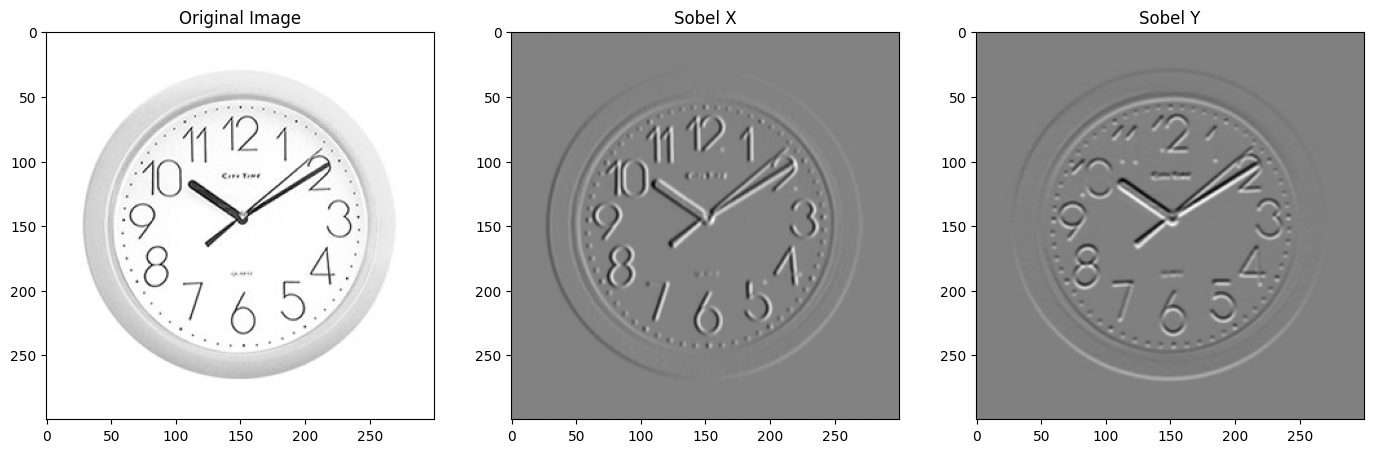

In [4]:
img = cv2.imread('images/clock.jpg', 0)

img_blur = cv2.blur(img, (3, 3))

sobel_x = np.array(
    [[-1, 0, 1],
     [-2, 0, 2],
     [-1, 0, 1]]
)

sobel_y = np.array(
    [[-1, -2, -1],
     [0, 0, 0],
     [1, 2, 1]]
)

img_sobel_x = cv2.filter2D(img_blur, cv2.CV_32F, sobel_x)
img_sobel_y = cv2.filter2D(img_blur, cv2.CV_32F, sobel_y)

plt.figure(figsize=(17, 8))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(img_sobel_x, cmap='gray')
plt.title('Sobel X')

plt.subplot(1, 3, 3)
plt.imshow(img_sobel_y, cmap='gray')
plt.title('Sobel Y')

plt.show()

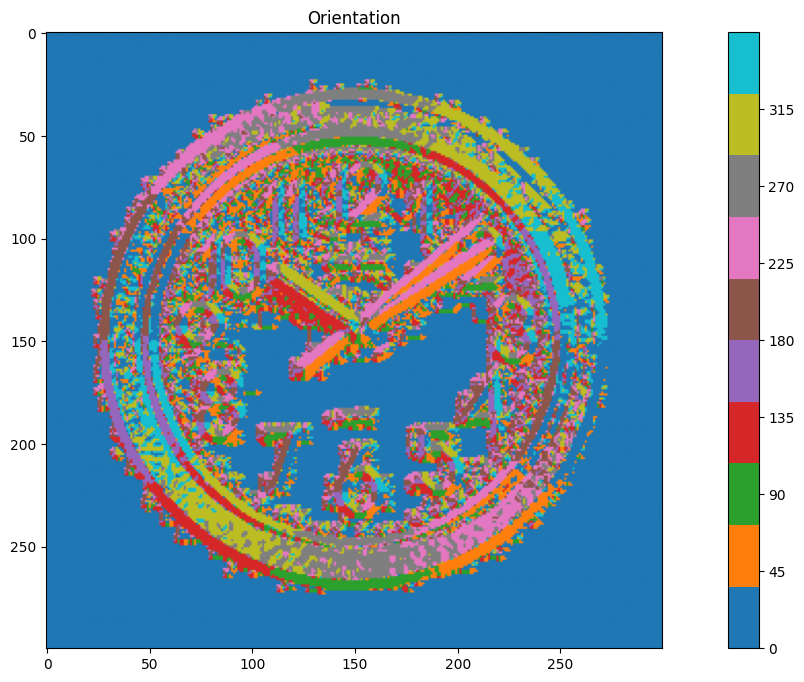

In [5]:
orien = cv2.phase(np.array(img_sobel_x, np.float32), np.array(img_sobel_y, np.float32), angleInDegrees=True)

plt.figure(figsize=(17, 8))

bounds = np.arange(0, 360, 45)

plt.imshow(orien, cmap='tab10')
plt.colorbar(ticks = bounds)
plt.title('Orientation')

plt.show()